In [1]:
import torch
import numpy as np

In [ ]:
import torch, torchvision
print(torch.__version__, torchvision.__version__)

2.9.1 0.24.1


In [4]:
import h5py

Tensors are a specialized data structure that are very similar to arrays and matrices. In PyTorch, we use tensors to encode the inputs and outputs of a model, as well as the model’s parameters.

Tensors are similar to NumPy’s ndarrays, except that tensors can run on GPUs or other hardware accelerators. In fact, tensors and NumPy arrays can often share the same underlying memory, eliminating the need to copy data

Tensors are also optimized for automatic differentiation 

In [2]:
data = [[1, 2],[3, 4]]
x_data = torch.tensor(data)
x_data

tensor([[1, 2],
        [3, 4]])

In [3]:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)
x_np

tensor([[1, 2],
        [3, 4]])

In [4]:
(x_data) == (x_np)

tensor([[True, True],
        [True, True]])

In [5]:
x_ones = torch.ones_like(x_data) # retains the properties of x_data
print(f"Ones Tensor: \n {x_ones} \n")

x_rand = torch.rand_like(x_data, dtype=torch.float) # overrides the datatype of x_data
print(f"Random Tensor: \n {x_rand} \n")

Ones Tensor: 
 tensor([[1, 1],
        [1, 1]]) 

Random Tensor: 
 tensor([[0.5623, 0.8393],
        [0.8890, 0.3489]]) 



In [6]:
shape = (2,3,)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor: \n {rand_tensor} \n")
print(f"Ones Tensor: \n {ones_tensor} \n")
print(f"Zeros Tensor: \n {zeros_tensor}")

Random Tensor: 
 tensor([[0.4618, 0.0249, 0.7054],
        [0.5851, 0.4434, 0.0148]]) 

Ones Tensor: 
 tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

Zeros Tensor: 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


In [7]:
tensor = torch.rand(3,4)

print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


In [8]:
torch.accelerator.is_available()

True

In [9]:
torch.accelerator.current_accelerator()

device(type='mps')

In [10]:
# We move our tensor to the current accelerator if available
if torch.accelerator.is_available():
    tensor = tensor.to(torch.accelerator.current_accelerator())

In [11]:
print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: mps:0


In [12]:
tensor = torch.ones(3, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[..., -1]}")
tensor[:,1] = 0
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1.])
Last column: tensor([1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [13]:
print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


In [14]:
tensor.shape

torch.Size([3, 4])

In [15]:
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)
t1.shape

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


torch.Size([3, 12])

In [16]:
t3 = torch.stack([tensor, tensor, tensor])
t3.shape

torch.Size([3, 3, 4])

In [17]:
t2 = torch.stack([tensor, tensor, tensor], dim=1)
t2.shape

torch.Size([3, 3, 4])

In [18]:
t4 = torch.stack([tensor, tensor, tensor], dim=2)
t4.shape

torch.Size([3, 4, 3])

In [19]:
print(t1.shape)

print(t1.T.shape)

torch.Size([3, 12])
torch.Size([12, 3])


In [20]:
t1.T

tensor([[1., 1., 1.],
        [0., 0., 0.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [0., 0., 0.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [0., 0., 0.],
        [1., 1., 1.],
        [1., 1., 1.]])

In [21]:
print(tensor.shape)

print(tensor.T.shape)

torch.Size([3, 4])
torch.Size([4, 3])


#### This computes the matrix multiplication between two tensors. y1, y2, y3 will have the same value
``tensor.T`` returns the transpose of a tensor

In [22]:
y1 = tensor @ tensor.T
print(y1.shape)
y1

torch.Size([3, 3])


tensor([[3., 3., 3.],
        [3., 3., 3.],
        [3., 3., 3.]])

In [23]:
y2 = tensor.matmul(tensor.T)
print(y2.shape)
y2

torch.Size([3, 3])


tensor([[3., 3., 3.],
        [3., 3., 3.],
        [3., 3., 3.]])

In [24]:
y3 = torch.rand_like(y1)
torch.matmul(tensor, tensor.T, out=y3)
print(y3.shape)
y3


torch.Size([3, 3])


tensor([[3., 3., 3.],
        [3., 3., 3.],
        [3., 3., 3.]])

#### This computes the element-wise product. z1, z2, z3 will have the same value


In [25]:
z1 = tensor * tensor
print(z1.shape)
z1

torch.Size([3, 4])


tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])

In [26]:
z2 = tensor.mul(tensor)
print(z2.shape)
z2

torch.Size([3, 4])


tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])

In [27]:
z3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=z3)
print(z3.shape)
z3

torch.Size([3, 4])


tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])

In [28]:
agg = tensor.sum()
agg_item = agg.item()
print(agg_item, type(agg_item))

9.0 <class 'float'>


In [29]:
agg

tensor(9.)

In [30]:
## In-place operations Operations that store the result into the operand 
# are called in-place. They are denoted by a _ suffix

print(f"{tensor} \n")
tensor.add_(5)
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor([[6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.]])


In [31]:
# Tensor to NumPy array

t = torch.ones(5)
print(f"t: {t}")

n = t.numpy()
print(f"n: {n}")

t: tensor([1., 1., 1., 1., 1.])
n: [1. 1. 1. 1. 1.]


In [32]:
# A change in the tensor reflects in the NumPy array.

t.add_(1)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


In [33]:
# Changes in the NumPy array reflects in the tensor.

np.add(n, 1, out=n)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([3., 3., 3., 3., 3.])
n: [3. 3. 3. 3. 3.]


#### Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset to enable easy access to the samples.

In [34]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [37]:
train_data = datasets.PCAM(
    root="data",
    split="train",
    download=True,
    transform=ToTensor()
)



Downloading...
From (original): https://drive.google.com/uc?id=1Ka0XfEMiwgCYPdTI-vv6eUElOBnKFKQ2
From (redirected): https://drive.usercontent.google.com/download?id=1Ka0XfEMiwgCYPdTI-vv6eUElOBnKFKQ2&confirm=t&uuid=68bb2591-8904-497d-8123-ce977c794529
To: /Users/neetigoenka/Documents/pytorch-reset/data/pcam/camelyonpatch_level_2_split_train_x.h5.gz
100%|██████████| 6.42G/6.42G [13:18<00:00, 8.05MB/s]  
Downloading...
From: https://drive.google.com/uc?id=1269yhu3pZDP8UYFQs-NYs3FPwuK-nGSG
To: /Users/neetigoenka/Documents/pytorch-reset/data/pcam/camelyonpatch_level_2_split_train_y.h5.gz
100%|██████████| 21.4k/21.4k [00:00<00:00, 764kB/s]


In [38]:
val_data = datasets.PCAM(
    root="data",
    split="val",
    download=True,
    transform=ToTensor()
)



Downloading...
From (original): https://drive.google.com/uc?id=1hgshYGWK8V-eGRy8LToWJJgDU_rXWVJ3
From (redirected): https://drive.usercontent.google.com/download?id=1hgshYGWK8V-eGRy8LToWJJgDU_rXWVJ3&confirm=t&uuid=2877bc1f-7035-46cc-b6a2-4a07bf4b18e3
To: /Users/neetigoenka/Documents/pytorch-reset/data/pcam/camelyonpatch_level_2_split_valid_x.h5.gz
100%|██████████| 806M/806M [01:17<00:00, 10.4MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1bH8ZRbhSVAhScTS0p9-ZzGnX91cHT3uO
To: /Users/neetigoenka/Documents/pytorch-reset/data/pcam/camelyonpatch_level_2_split_valid_y.h5.gz
100%|██████████| 3.04k/3.04k [00:00<00:00, 3.06MB/s]


In [39]:
test_data = datasets.PCAM(
    root="data",
    split="test",
    download=True,
    transform=ToTensor()
)

Downloading...
From (original): https://drive.google.com/uc?id=1qV65ZqZvWzuIVthK8eVDhIwrbnsJdbg_
From (redirected): https://drive.usercontent.google.com/download?id=1qV65ZqZvWzuIVthK8eVDhIwrbnsJdbg_&confirm=t&uuid=a4ec0728-6e94-401f-b3c0-4bcdf6f4b5ed
To: /Users/neetigoenka/Documents/pytorch-reset/data/pcam/camelyonpatch_level_2_split_test_x.h5.gz
100%|██████████| 801M/801M [01:18<00:00, 10.2MB/s] 
Downloading...
From: https://drive.google.com/uc?id=17BHrSrwWKjYsOgTMmoqrIjDy6Fa2o_gP
To: /Users/neetigoenka/Documents/pytorch-reset/data/pcam/camelyonpatch_level_2_split_test_y.h5.gz
100%|██████████| 3.04k/3.04k [00:00<00:00, 9.65MB/s]


In [43]:
len(train_data), len(val_data), len(test_data)

(262144, 32768, 32768)

In [44]:
len(train_data[0])

2

In [53]:
img, label = train_data[0]

In [55]:
label

0

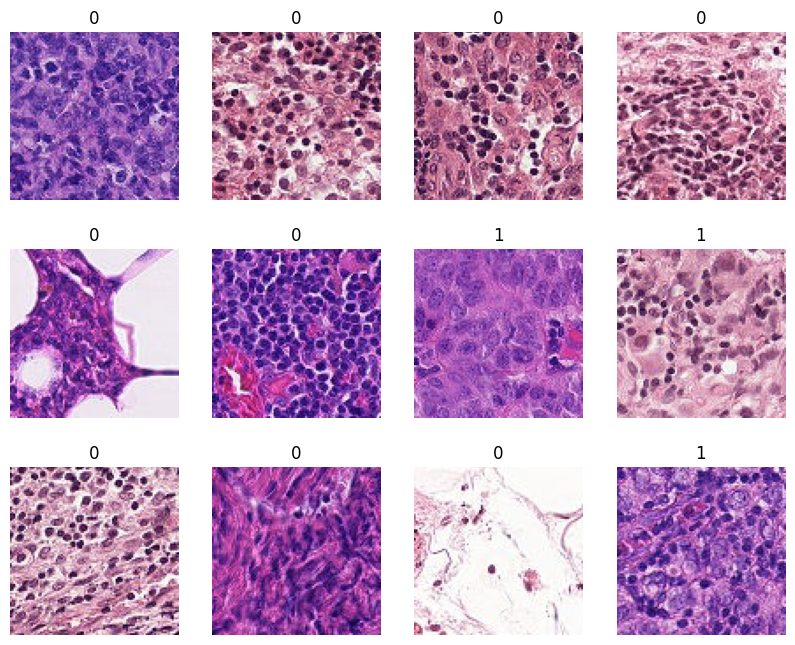

In [ ]:
figure = plt.figure(figsize=(10, 8))
cols, rows = 4, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_data), size=(1,)).item()
    img, label = train_data[sample_idx]
    # converting from (C, H, W) to (H, W, C) for matplotlib
    img = img.permute(1, 2, 0)
    figure.add_subplot(rows, cols, i)
    plt.title(label)
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [ ]:
import h5py
import torch
from torch.utils.data import Dataset

## A custom Dataset class must implement three functions: __init__, __len__, and __getitem__. 
class PCAMDataset(Dataset):
    def __init__(self, x_path, y_path, transform=None):
        self.x_file = h5py.File(x_path, "r")
        self.y_file = h5py.File(y_path, "r")
        
        self.x = self.x_file["x"]
        self.y = self.y_file["y"]
        self.transform = transform

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        image = self.x[idx]          # (96,96,3), uint8
        label = int(self.y[idx])     # scalar

        if self.transform:
            image = self.transform(image)
        else:
            # fallback: convert to tensor
            image = torch.from_numpy(image).permute(2,0,1).float() / 255.0

        return image, label

In [84]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),   # HWC uint8 → CHW float [0,1]
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Why everyone uses ImageNet normalization

1️⃣ Pretrained models expect it

If you use:
	•	ResNet
	•	EfficientNet
	•	MobileNet
	•	ViT
	•	ConvNeXt

pretrained on ImageNet, the weights were learned assuming this input distribution.

If you don’t normalize this way:
	•	activations shift
	•	BatchNorm statistics mismatch
	•	convergence slows or breaks

In [85]:
from torch.utils.data import DataLoader

train_dataset = PCAMDataset(
    x_path="data/pcam/camelyonpatch_level_2_split_train_x.h5",
    y_path="data/pcam/camelyonpatch_level_2_split_train_y.h5",
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

In [86]:
images, labels = next(iter(train_loader))
print(images.shape)  # (B, 3, 96, 96)
print(labels.shape)  # (B,)

torch.Size([64, 3, 96, 96])
torch.Size([64])


/var/folders/sm/n2hk31c12wv5pm94flx90n4m0000gn/T/ipykernel_87387/1683610910.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  label = int(self.y[idx])     # scalar


In [87]:
def compute_mean_std(loader):
    mean = 0.
    std = 0.
    total = 0.

    for images, _ in loader:
        b, c, h, w = images.shape
        images = images.view(b, c, -1)
        mean += images.mean(2).sum(0)
        std += images.std(2).sum(0)
        total += b

    mean /= total
    std /= total
    return mean, std



In [88]:
mean , std = compute_mean_std(train_loader)
print(f"Mean: {mean}")
print(f"Std: {std}")

/Users/neetigoenka/Documents/pytorch-reset/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/var/folders/sm/n2hk31c12wv5pm94flx90n4m0000gn/T/ipykernel_87387/1683610910.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  label = int(self.y[idx])     # scalar


Mean: tensor([0.9422, 0.3677, 1.2694])
Std: tensor([0.7937, 0.8966, 0.7325])
